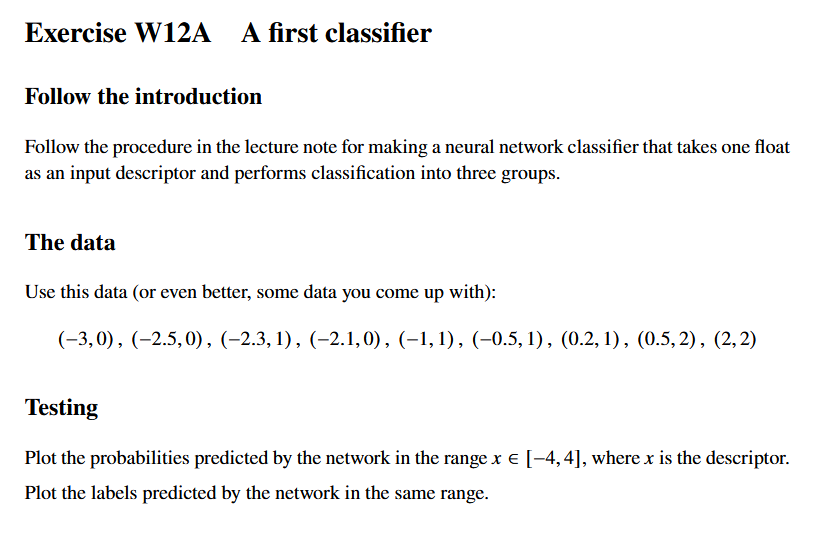

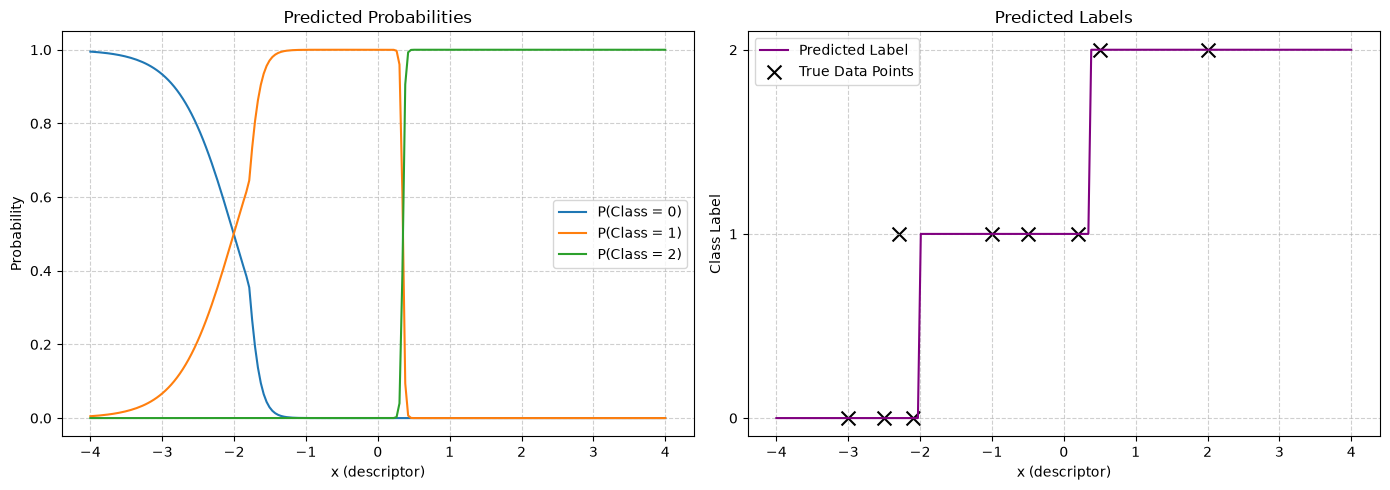

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

data = [(-3, 0), (-2.5, 0), (-2.3, 1), (-2.1, 0), (-1, 1), 
        (-0.5, 1), (0.2, 1), (0.5, 2), (2, 2)]

X_train = torch.tensor([[d[0]] for d in data], dtype=torch.float32)
y_train = torch.tensor([d[1] for d in data], dtype=torch.long)

class SimpleClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 3) 
        )

    def forward(self, x):
        return self.network(x)
        
    def fit(self, X, y, epochs=1500, lr=0.01):
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(self.parameters(), lr=lr)
        
        self.train()
        for epoch in range(epochs):
            optimizer.zero_grad()
            logits = self(X)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            
    def classify(self, X):
        self.eval()
        with torch.no_grad():
            logits = self(X)
            probabilities = torch.softmax(logits, dim=1)
            predicted_labels = torch.argmax(probabilities, dim=1)
        return probabilities, predicted_labels

model = SimpleClassifier()
model.fit(X_train, y_train)

x_test = torch.linspace(-4, 4, 200).unsqueeze(1)
probabilities, predicted_labels = model.classify(x_test)

x_plot = x_test.numpy().flatten()
probs_plot = probabilities.numpy()
preds_plot = predicted_labels.numpy()
x_orig = [d[0] for d in data]
y_orig = [d[1] for d in data]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(x_plot, probs_plot[:, 0], label="P(Class = 0)")
ax1.plot(x_plot, probs_plot[:, 1], label="P(Class = 1)")
ax1.plot(x_plot, probs_plot[:, 2], label="P(Class = 2)")
ax1.set_title("Predicted Probabilities")
ax1.set_xlabel("x (descriptor)")
ax1.set_ylabel("Probability")
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(x_plot, preds_plot, color='purple', label="Predicted Label")
ax2.scatter(x_orig, y_orig, color='black', marker='x', s=100, label="True Data Points")
ax2.set_title("Predicted Labels")
ax2.set_xlabel("x (descriptor)")
ax2.set_ylabel("Class Label")
ax2.set_yticks([0, 1, 2])
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()